# E2 · Diseño de experimentos: configuración del extractor del SNIIM

**Observatorio Antojo Colima** · Data Statistician y Quality Lead de E2: Avlix Eduardo Jiménez Cuevas

**Pregunta de ingeniería.** ¿Qué configuración del extractor procesa más rápido las páginas de resultados del SNIIM **sin perder filas**?

| Factor | Bajo (−1) | Alto (+1) | Por qué puede importar |
|---|---|---|---|
| A · procesos | 1 | 4 | Leer páginas en paralelo reparte el trabajo, pero arrancar procesos cuesta |
| B · parser | `html.parser` | `lxml` | Motor que interpreta el HTML: velocidad y tolerancia a HTML mal formado |
| C · formato | CSV | Parquet | Escribir el resultado: texto contra columnar comprimido |
| D · lote (solo 2⁴) | 1 | 25 | Páginas por tarea que recibe cada proceso |

**Respuestas.** `tiempo_s`: segundos de reloj para leer las 220 páginas y guardar el resultado, incluido el arranque de los procesos. `tasa_error`: % de las 66,625 filas esperadas que se perdieron o se leyeron con otro contenido.

**Unidad experimental.** Una corrida completa sobre el banco local (`laboratorio/banco_sniim.py`): 220 páginas con la estructura real del SNIIM, las filas reales de Colima y 26 páginas dañadas a propósito (descarga cortada, celdas sin cerrar, tabla con otro id, acentos dañados). Se usa un banco local para que la latencia de la red no se confunda con los factores y para no cargar al servidor del SNIIM.

**Control del ruido.** *Aleatorización:* el orden de las corridas se sortea en cada bloque con una semilla registrada. *Réplicas:* 3. *Bloqueo:* cada réplica se corre en una sesión distinta (mañana, tarde, noche); la sesión entra al modelo como bloque. Antes de cada sesión hay una corrida de calentamiento que no se registra y no se usa la computadora para otra cosa mientras corre.

**Configuración actual del extractor** (la línea base): 1 proceso, `html.parser`, CSV.

In [1]:
import sys
import warnings
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "laboratorio" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats

from laboratorio import analisis_doe as doe

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
AZUL, NARANJA, VERDE, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#898781"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "axes.axisbelow": True,
    }
)
F3 = ["procesos", "parser", "formato"]
d3 = doe.cargar("2k3")
bif = doe.cargar("bifactorial")
print(f"2^3: {len(d3)} corridas en {d3['bloque'].nunique()} bloques · bifactorial: {len(bif)} corridas")
d3.groupby(["bloque", "sesion"]).agg(
    corridas=("orden", "count"), semilla=("semilla", "first"), primera=("inicio_utc", "min"), ultima=("inicio_utc", "max")
)

2^3: 24 corridas en 3 bloques · bifactorial: 18 corridas


,,corridas,semilla,primera,ultima
bloque,sesion,,,,
1,viernes manana,8,2156516688,2026-11-20T15:37:43+00:00,2026-11-20T15:39:00+00:00
2,viernes tarde,8,427853034,2026-11-20T19:51:13+00:00,2026-11-20T19:54:44+00:00
3,viernes noche,8,1854387324,2026-11-21T03:47:18+00:00,2026-11-21T03:48:39+00:00


## 1. Aleatorización: orden real de las corridas

Cada bloque tiene su propio orden sorteado. La columna `corrida_std` es el número de la combinación en orden estándar (Yates) y `orden` es la posición en la que realmente se corrió.

In [2]:
d3.pivot_table(index="corrida_std", columns="bloque", values="orden").astype(int).rename_axis(
    index="corrida estándar", columns="bloque → orden en que se corrió"
)

bloque → orden en que se corrió,1,2,3
corrida estándar,,,
1,1,2,3
2,2,8,7
3,7,5,8
4,8,6,1
5,6,3,4
6,3,7,5
7,4,4,2
8,5,1,6


## 2. Tasa de error: depende solo del parser

La tasa de error no varía entre réplicas, sesiones, número de procesos ni formato: para un mismo parser, el resultado es idéntico byte por byte. Por eso no se le aplica ANOVA (no hay varianza dentro de los tratamientos); se reporta como tabla y se explica por qué ocurre, página dañada por página dañada.

In [3]:
err = pd.concat([d3, bif]).groupby("parser_valor")["tasa_error"].agg(["mean", "std", "min", "max", "count"])
err

,mean,std,min,max,count
parser_valor,,,,,
html.parser,8.4950,0.0000,8.4950,8.4950,21
lxml,5.0030,0.0000,5.0030,5.0030,21


In [4]:
import json

from laboratorio.banco_sniim import BANCO, PAGINAS, leer_pagina

man = pd.read_csv(BANCO / "manifiesto.csv")
if (BANCO / "esperado.json").exists():
    esperado = json.loads((BANCO / "esperado.json").read_text(encoding="utf-8"))
    filas = []
    for _, p in man[man["dano"] != "ninguno"].iterrows():
        for parser in ["html.parser", "lxml"]:
            _, leidas = leer_pagina((str(PAGINAS / p["pagina"]), parser))
            objetivo = [tuple(f) for f in esperado[p["pagina"]]]
            s = set(leidas)
            filas.append(
                {"dano": p["dano"], "parser": parser, "esperadas": len(objetivo), "mal_leidas": sum(f not in s for f in objetivo)}
            )
    por_dano = pd.DataFrame(filas).groupby(["dano", "parser"])[["esperadas", "mal_leidas"]].sum()
    por_dano["pct_mal_leidas"] = 100 * por_dano["mal_leidas"] / por_dano["esperadas"]
    display(por_dano.unstack("parser").round(1))
else:
    print("El banco no está generado: python -m laboratorio.banco_sniim generar")

esperadas        mal_leidas       pct_mal_leidas         
parser      html.parser  lxml html.parser  lxml    html.parser     lxml
dano                                                                   
mojibake           1378  1378         636   636        46.2000  46.2000
sin_cierres        2327  2327        2327     0       100.0000   0.0000
sin_id             1755  1755        1755  1755       100.0000 100.0000
truncada           2340  2340         942   942        40.3000  40.3000

**Lectura.** La diferencia completa entre parsers está en las páginas con **celdas sin `</td>`**: `html.parser` no sabe que una celda nueva cierra la anterior, anida cada celda dentro de la previa y `get_text()` devuelve textos pegados (`"02/10/2020KilogramoJalisco…"`). La fila sigue teniendo 8 celdas, así que **pasa el filtro del extractor y se guarda con contenido equivocado, sin ningún aviso**. `lxml` aplica las reglas de HTML5 para cierres implícitos y lee esas filas perfectas. Los otros tres daños (descarga cortada, tabla con otro id y acentos dañados) los sufren igual ambos parsers: esos se atienden con la puerta de calidad y con los reintentos, no con el parser.

## 3. Diseño factorial 2³ con 3 réplicas y bloques

Modelo: $y_{ijkl} = \mu + \tau_i + \beta_j + \gamma_k + (\tau\beta)_{ij} + (\tau\gamma)_{ik} + (\beta\gamma)_{jk} + (\tau\beta\gamma)_{ijk} + \delta_l + \varepsilon_{ijkl}$, donde $\delta_l$ es el efecto del bloque (sesión). Factores codificados en −1/+1.

### 3.1 Matriz del diseño y respuestas

In [5]:
matriz = d3.pivot_table(index=["corrida_std"] + F3, columns="bloque", values="tiempo_s").reset_index()
matriz.columns = [str(c) if c in F3 + ["corrida_std"] else f"tiempo bloque {c}" for c in matriz.columns]
matriz["media"] = matriz.filter(like="tiempo").mean(axis=1)
matriz["desv"] = matriz.filter(like="tiempo bloque").std(axis=1)
matriz.insert(
    1,
    "configuración",
    d3.drop_duplicates("corrida_std")
    .set_index("corrida_std")
    .loc[matriz["corrida_std"], ["procesos_valor", "parser_valor", "formato_valor"]]
    .astype(str)
    .agg(" · ".join, axis=1)
    .values,
)
matriz

,corrida_std,configuración,procesos,parser,formato,tiempo bloque 1,tiempo bloque 2,tiempo bloque 3,media,desv
0,1,1 · html.parser · csv,-1,-1,-1,19.7975,47.1271,20.0014,28.9753,15.7202
1,2,4 · html.parser · csv,1,-1,-1,7.7262,18.0823,7.1834,10.9973,6.1418
2,3,1 · lxml · csv,-1,1,-1,14.4766,33.4493,14.5235,20.8165,10.9404
3,4,4 · lxml · csv,1,1,-1,6.2102,13.9112,5.7089,8.6101,4.5977
4,5,1 · html.parser · parquet,-1,-1,1,19.6214,48.0607,20.0205,29.2342,16.3054
5,6,4 · html.parser · parquet,1,-1,1,7.7289,17.7345,7.0533,10.8389,5.9813
6,7,1 · lxml · parquet,-1,1,1,14.1802,34.4963,14.6373,21.1046,11.5998
7,8,4 · lxml · parquet,1,1,1,5.8263,14.3776,5.5337,8.5792,5.0237


### 3.2 ANOVA en la escala original (α = 0.05)

In [6]:
m3 = doe.modelo_2k(d3, F3)
anova3 = doe.tabla_anova(m3)
print(f"R² = {m3.rsquared:.4f} · R² ajustado = {m3.rsquared_adj:.4f} · CM error = {m3.mse_resid:.4f} con {int(m3.df_resid)} gl")
anova3

R² = 0.9058 · R² ajustado = 0.8452 · CM error = 22.8172 con 14 gl


,SC,gl,CM,F0,valor_p,significativo
Bloque (sesión),"1,454.7882",2.0000,727.3941,31.8792,0.0000,True
A (procesos),"1,400.1875",1.0000,"1,400.1875",61.3654,0.0000,True
B (parser),164.3586,1.0000,164.3586,7.2033,0.0178,True
AB (procesos × parser),50.8223,1.0000,50.8223,2.2274,0.1578,False
C (formato),0.0480,1.0000,0.0480,0.0021,0.9641,False
AC (procesos × formato),0.2033,1.0000,0.2033,0.0089,0.9261,False
BC (parser × formato),0.0092,1.0000,0.0092,0.0004,0.9842,False
ABC (procesos × parser × formato),0.0036,1.0000,0.0036,0.0002,0.9901,False
Error,319.4410,14.0000,22.8172,NaN,NaN,False


### 3.3 Efectos estimados

,termino,factores,efecto,error_estandar,t0,valor_p,significativo
0,A,procesos,-15.2763,1.9501,-7.8336,0.0000,True
1,B,parser,-5.2338,1.9501,-2.6839,0.0178,True
2,AB,procesos × parser,2.9104,1.9501,1.4924,0.1578,False
3,AC,procesos × formato,-0.1841,1.9501,-0.0944,0.9261,False
4,C,formato,0.0894,1.9501,0.0459,0.9641,False
5,BC,parser × formato,0.0392,1.9501,0.0201,0.9842,False
6,ABC,procesos × parser × formato,0.0246,1.9501,0.0126,0.9901,False


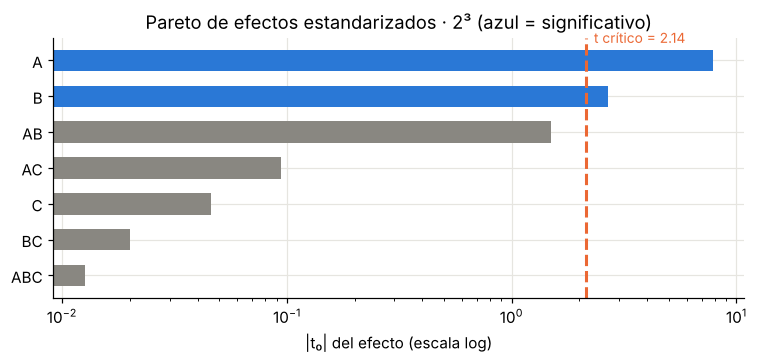

In [7]:
ef3 = doe.efectos(m3, F3)
display(ef3)
t_crit = stats.t.ppf(0.975, m3.df_resid)
fig, ax = plt.subplots(figsize=(7, 3.4))
colores = [AZUL if s else GRIS for s in ef3["significativo"]]
ax.barh(ef3["termino"][::-1], ef3["t0"].abs()[::-1], color=colores[::-1], height=0.6)
ax.axvline(t_crit, color=NARANJA, lw=2, ls="--")
ax.text(t_crit, len(ef3) - 0.6, f"  t crítico = {t_crit:.2f}", color=NARANJA, va="bottom", fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("|t₀| del efecto (escala log)")
ax.set_title("Pareto de efectos estandarizados · 2³ (azul = significativo)")
plt.tight_layout()
plt.show()

### 3.4 Gráficas de efectos principales e interacción

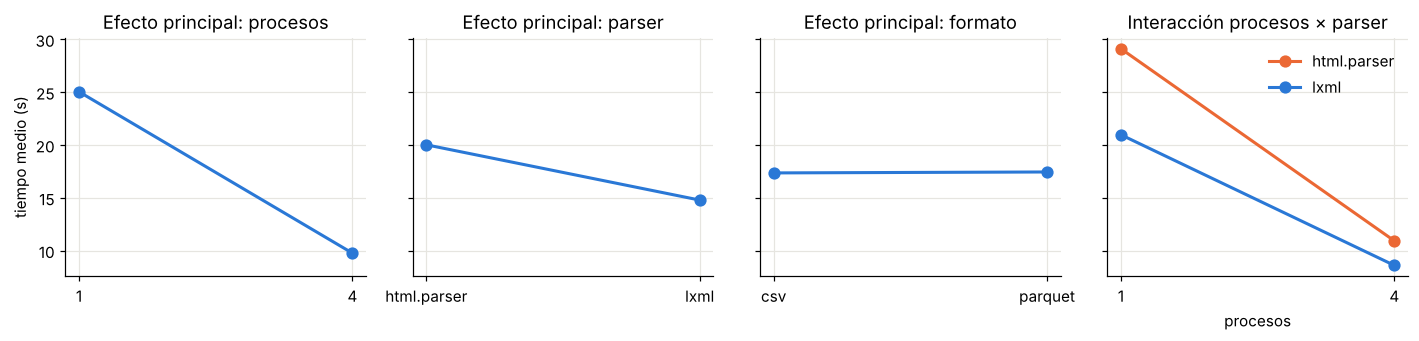

In [8]:
fig, axs = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for ax, f in zip(axs[:3], F3, strict=False):
    g = d3.groupby(f"{f}_valor")["tiempo_s"].mean()
    ax.plot(g.index.astype(str), g.values, "o-", color=AZUL, lw=2, ms=7)
    ax.set_title(f"Efecto principal: {f}")
    ax.set_xlabel("")
axs[0].set_ylabel("tiempo medio (s)")
ax = axs[3]
for parser, color in [("html.parser", NARANJA), ("lxml", AZUL)]:
    g = d3[d3["parser_valor"] == parser].groupby("procesos_valor")["tiempo_s"].mean()
    ax.plot(g.index.astype(str), g.values, "o-", color=color, lw=2, ms=7, label=parser)
ax.set_title("Interacción procesos × parser")
ax.set_xlabel("procesos")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### 3.5 Verificación de supuestos (residuos)

Shapiro-Wilk W = 0.9272, p = 0.0844  (H0: residuos normales)
Levene p = 0.9823  (H0: misma varianza en los 8 tratamientos)
Durbin-Watson = 1.713  (≈ 2: sin autocorrelación en el orden de corrida)


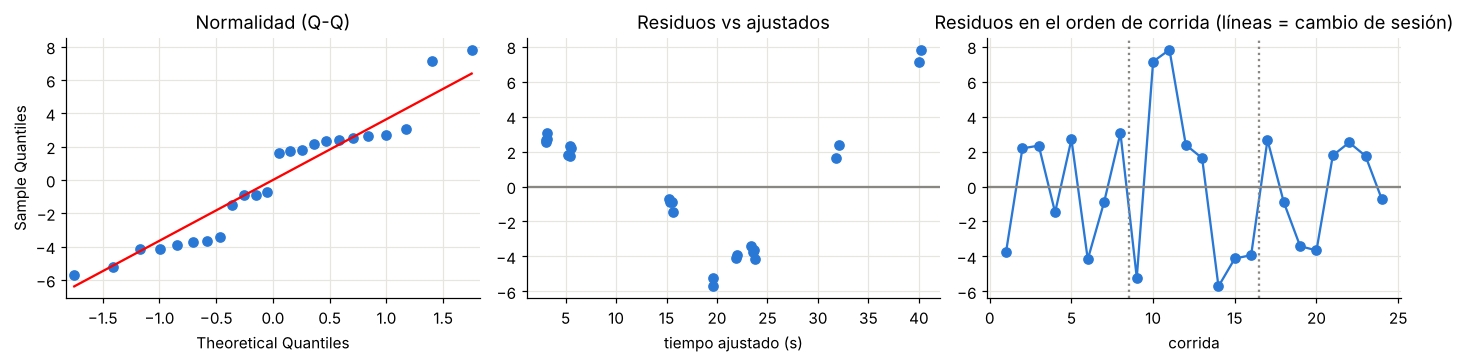

In [9]:
sup3 = doe.supuestos(m3, F3)
print(f"Shapiro-Wilk W = {sup3['shapiro_W']:.4f}, p = {sup3['shapiro_p']:.4f}  (H0: residuos normales)")
print(f"Levene p = {sup3['levene_p']:.4f}  (H0: misma varianza en los 8 tratamientos)")
print(f"Durbin-Watson = {sup3['durbin_watson']:.3f}  (≈ 2: sin autocorrelación en el orden de corrida)")
r = m3.resid
aj = m3.fittedvalues
orden_global = d3["bloque"].astype(int) * 100 + d3["orden"]
fig, axs = plt.subplots(1, 3, figsize=(13, 3.4))
sm.qqplot(r, line="s", ax=axs[0], markerfacecolor=AZUL, markeredgecolor=AZUL)
axs[0].set_title("Normalidad (Q-Q)")
axs[1].scatter(aj, r, color=AZUL)
axs[1].axhline(0, color=GRIS)
axs[1].set_title("Residuos vs ajustados")
axs[1].set_xlabel("tiempo ajustado (s)")
o = np.argsort(orden_global.values)
axs[2].plot(np.arange(1, len(r) + 1), r.values[o], "o-", color=AZUL)
axs[2].axhline(0, color=GRIS)
for b in range(1, d3["bloque"].nunique()):
    axs[2].axvline(b * 8 + 0.5, color=GRIS, ls=":")
axs[2].set_title("Residuos en el orden de corrida (líneas = cambio de sesión)")
axs[2].set_xlabel("corrida")
plt.tight_layout()
plt.show()

### 3.6 ¿Hace falta transformar? (Box-Cox)

El paralelismo **divide** el tiempo (efecto multiplicativo), así que la interacción AB podría ser solo un efecto de escala. Se revisa con Box-Cox y se repite el ANOVA en escala logarítmica.

In [10]:
_, lam = stats.boxcox(d3["tiempo_s"])
print(f"λ de Box-Cox = {lam:.3f}  (λ ≈ 0 sugiere logaritmo; λ ≈ 1, ninguna transformación)")
m3log = doe.modelo_2k(d3.assign(log_tiempo=np.log(d3["tiempo_s"])), F3, "log_tiempo")
sup_log = doe.supuestos(m3log, F3)
print(f"Escala log · R² = {m3log.rsquared:.4f} · Shapiro p = {sup_log['shapiro_p']:.4f} · Levene p = {sup_log['levene_p']:.4f}")
doe.tabla_anova(m3log)

λ de Box-Cox = -0.156  (λ ≈ 0 sugiere logaritmo; λ ≈ 1, ninguna transformación)
Escala log · R² = 0.9987 · Shapiro p = 0.0431 · Levene p = 0.9992


,SC,gl,CM,F0,valor_p,significativo
Bloque (sesión),4.0840,2.0000,2.0420,"2,243.3863",0.0000,True
A (procesos),5.3106,1.0000,5.3106,"5,834.2977",0.0000,True
B (parser),0.4791,1.0000,0.4791,526.3460,0.0000,True
AB (procesos × parser),0.0104,1.0000,0.0104,11.4426,0.0045,True
C (formato),0.0002,1.0000,0.0002,0.2229,0.6441,False
AC (procesos × formato),0.0007,1.0000,0.0007,0.7609,0.3978,False
BC (parser × formato),0.0000,1.0000,0.0000,0.0154,0.9030,False
ABC (procesos × parser × formato),0.0000,1.0000,0.0000,0.0439,0.8371,False
Error,0.0127,14.0000,0.0009,NaN,NaN,False


## 4. Mejor combinación y tamaño de la mejora

**Modelo final: log(tiempo).** Box-Cox da λ cercano a 0, y la sesión lenta multiplicó todos los tiempos por casi el mismo factor: el efecto del bloque es multiplicativo. En escala log ese efecto se vuelve aditivo y se cancela al comparar dos configuraciones en la misma sesión. Por eso la mejora se reporta como **razón de tiempos** (cuántas veces más rápido), que no depende de la sesión.

**Elección.** A (4 procesos) y B (`lxml`) reducen el tiempo y son significativos; C (formato) no lo es en ninguna escala. Entre CSV y Parquet se queda **CSV**: no cambia el tiempo, es el formato que ya usa bronce, se lee sin librerías extra y se revisa a simple vista.

In [11]:
display(doe.medias_por_combinacion(d3, F3))
BASE = {"procesos": 1, "parser": "html.parser", "formato": "csv"}
MEJOR = {"procesos": 4, "parser": "lxml", "formato": "csv"}
cod = {"procesos": {1: -1, 4: 1}, "parser": {"html.parser": -1, "lxml": 1}, "formato": {"csv": -1, "parquet": 1}}
base_c = {k: cod[k][v] for k, v in BASE.items()}
mejor_c = {k: cod[k][v] for k, v in MEJOR.items()}
rz = doe.razon_predicha(m3log, base_c, mejor_c, nuevas=5)
por_bloque = doe.razones_por_bloque(d3, BASE, MEJOR)
display(por_bloque)
err_base = d3.loc[d3["parser_valor"] == BASE["parser"], "tasa_error"].iloc[0]
err_mejor = d3.loc[d3["parser_valor"] == MEJOR["parser"], "tasa_error"].iloc[0]
print(f"Configuración actual: {BASE}")
print(f"Mejor configuración:  {MEJOR}")
ic, icr, ip = rz["ic95"], rz["ic95_reduccion_pct"], rz["ip95"]
print(f"Tiempo: {rz['razon']:.2f} veces más rápido (IC 95 % {ic[0]:.2f} a {ic[1]:.2f}),")
print(f"  es decir, {rz['reduccion_pct']:.1f} % menos tiempo (IC 95 % {icr[0]:.1f} a {icr[1]:.1f} %).")
vmin, vmax = por_bloque["veces_mas_rapido"].min(), por_bloque["veces_mas_rapido"].max()
print(f"En las 3 sesiones por separado: de {vmin:.2f} a {vmax:.2f} veces más rápido.")
filas_mejor = d3["filas_esperadas"].iloc[0] * (err_base - err_mejor) / 100
print(f"Tasa de error: {err_base:.3f} % → {err_mejor:.3f} %: {filas_mejor:,.0f} filas más bien leídas por corrida.")
print(f"Predicción para la confirmación (5 y 5 corridas en una sesión nueva): razón entre {ip[0]:.2f} y {ip[1]:.2f}.")

,procesos_valor,parser_valor,formato_valor,media,desv,n
0,4,lxml,parquet,8.5792,5.0237,3
1,4,lxml,csv,8.6101,4.5977,3
2,4,html.parser,parquet,10.8389,5.9813,3
3,4,html.parser,csv,10.9973,6.1418,3
4,1,lxml,csv,20.8165,10.9404,3
5,1,lxml,parquet,21.1046,11.5998,3
6,1,html.parser,csv,28.9753,15.7202,3
7,1,html.parser,parquet,29.2342,16.3054,3


,bloque,sesion,actual_s,mejor_s,veces_mas_rapido
0,1,viernes manana,19.7975,6.2102,3.1879
1,2,viernes tarde,47.1271,13.9112,3.3877
2,3,viernes noche,20.0014,5.7089,3.5035


Configuración actual: {'procesos': 1, 'parser': 'html.parser', 'formato': 'csv'}
Mejor configuración:  {'procesos': 4, 'parser': 'lxml', 'formato': 'csv'}
Tiempo: 3.36 veces más rápido (IC 95 % 3.18 a 3.54),
  es decir, 70.2 % menos tiempo (IC 95 % 68.6 a 71.7 %).
En las 3 sesiones por separado: de 3.19 a 3.50 veces más rápido.
Tasa de error: 8.495 % → 5.003 %: 2,327 filas más bien leídas por corrida.
Predicción para la confirmación (5 y 5 corridas en una sesión nueva): razón entre 3.14 y 3.59.


## 5. Diseño bifactorial con un factor de 3 niveles

Procesos (1, 2, 4) × parser (`html.parser`, `lxml`), formato CSV y lote 10 fijos, 3 réplicas en los mismos 3 bloques. Pregunta: ¿el beneficio de agregar procesos es lineal o se satura?, ¿depende del parser?

Modelo en log(tiempo), como el 2^3 · R² = 0.9979 · CM error = 0.00130 con 10 gl


,SC,gl,CM,F0,valor_p,significativo
"Procesos (1, 2, 4)",2.6454,2.0000,1.3227,"1,016.0534",0.0000,True
Parser,0.3505,1.0000,0.3505,269.2746,0.0000,True
Bloque (sesión),3.2961,2.0000,1.6480,"1,265.9586",0.0000,True
Procesos × parser,0.0106,2.0000,0.0053,4.0550,0.0513,False
Error,0.0130,10.0000,0.0013,NaN,NaN,False


Shapiro p = 0.5218 · Levene p = 0.8031 · Durbin-Watson = 2.394


mean                 std        
parser_valor   html.parser    lxml html.parser    lxml
procesos_valor                                        
1                  29.8081 20.8754     17.4115 11.2342
2                  16.9369 12.8667      9.9527  7.5319
4                  11.0875  8.6797      6.6686  4.6339

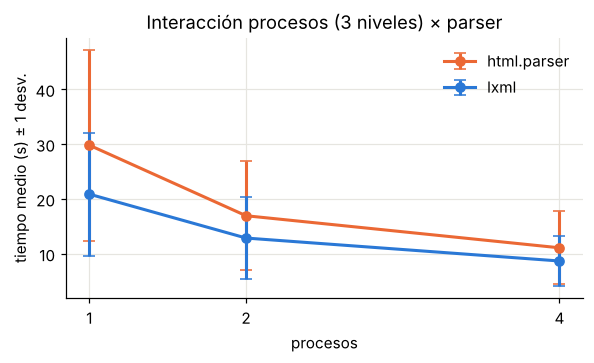


Tukey HSD entre niveles de procesos con html.parser (log(tiempo) ajustado por bloque):


Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower   upper  reject
---------------------------------------------------
     1      2  -0.5665   0.0 -0.5903 -0.5428   True
     1      4  -0.9952   0.0 -1.0189 -0.9714   True
     2      4  -0.4287   0.0 -0.4524 -0.4049   True
---------------------------------------------------

Tukey HSD entre niveles de procesos con lxml (log(tiempo) ajustado por bloque):


Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower   upper  reject
---------------------------------------------------
     1      2  -0.4998   0.0 -0.5949 -0.4047   True
     1      4  -0.8769   0.0  -0.972 -0.7818   True
     2      4  -0.3771   0.0 -0.4722  -0.282   True
---------------------------------------------------


In [12]:
mb = doe.modelo_bifactorial(bif.assign(log_tiempo=np.log(bif["tiempo_s"])), "log_tiempo")
print(f"Modelo en log(tiempo), como el 2^3 · R² = {mb.rsquared:.4f} · CM error = {mb.mse_resid:.5f} con {int(mb.df_resid)} gl")
display(doe.tabla_anova_bifactorial(mb))
supb = doe.supuestos(mb, ["procesos_valor", "parser_valor"])
print(f"Shapiro p = {supb['shapiro_p']:.4f} · Levene p = {supb['levene_p']:.4f} · Durbin-Watson = {supb['durbin_watson']:.3f}")
display(bif.pivot_table(index="procesos_valor", columns="parser_valor", values="tiempo_s", aggfunc=["mean", "std"]))
fig, ax = plt.subplots(figsize=(5.5, 3.4))
for parser, color in [("html.parser", NARANJA), ("lxml", AZUL)]:
    g = bif[bif["parser_valor"] == parser].groupby("procesos_valor")["tiempo_s"]
    ax.errorbar(g.mean().index, g.mean().values, yerr=g.std().values, fmt="o-", color=color, lw=2, capsize=4, label=parser)
ax.set_xticks([1, 2, 4])
ax.set_xlabel("procesos")
ax.set_ylabel("tiempo medio (s) ± 1 desv.")
ax.legend(frameon=False)
ax.set_title("Interacción procesos (3 niveles) × parser")
plt.tight_layout()
plt.show()
for parser in ["html.parser", "lxml"]:
    print(f"\nTukey HSD entre niveles de procesos con {parser} (log(tiempo) ajustado por bloque):")
    print(doe.tukey_procesos(bif, parser))

## 6. 2⁴ completo contra media fracción 2⁴⁻¹

Se agrega D · lote (1 contra 25 páginas por tarea). El 2⁴ completo son 16 corridas (una réplica, bloque 2). La media fracción usa el generador **D = ABC**, es decir, la relación de definición **I = ABCD**: son las 8 corridas del 2⁴ con A·B·C·D = +1. Así se puede comparar qué se aprende con la mitad del costo.

### 6.1 Matrices

In [13]:
from laboratorio.experimento import plan

p4 = plan("2k4")
p4["ABCD"] = p4["procesos"] * p4["parser"] * p4["formato"] * p4["lote"]
display(p4.rename(columns={"procesos": "A", "parser": "B", "formato": "C", "lote": "D"}))
print("Media fracción 2^(4-1), I = ABCD (D = ABC):")
display(p4[p4["en_media_fraccion"]].rename(columns={"procesos": "A", "parser": "B", "formato": "C", "lote": "D"}))

,corrida_std,A,B,C,D,en_media_fraccion,ABCD
0,1,-1,-1,-1,-1,True,1
1,2,1,-1,-1,-1,False,-1
2,3,-1,1,-1,-1,False,-1
3,4,1,1,-1,-1,True,1
4,5,-1,-1,1,-1,False,-1
5,6,1,-1,1,-1,True,1
6,7,-1,1,1,-1,True,1
7,8,1,1,1,-1,False,-1
8,9,-1,-1,-1,1,False,-1
9,10,1,-1,-1,1,True,1


Media fracción 2^(4-1), I = ABCD (D = ABC):


,corrida_std,A,B,C,D,en_media_fraccion,ABCD
0,1,-1,-1,-1,-1,True,1
3,4,1,1,-1,-1,True,1
5,6,1,-1,1,-1,True,1
6,7,-1,1,1,-1,True,1
9,10,1,-1,-1,1,True,1
10,11,-1,1,-1,1,True,1
12,13,-1,-1,1,1,True,1
15,16,1,1,1,1,True,1


### 6.2 Estructura de alias de la media fracción (resolución IV)

In [14]:
display(doe.estructura_alias())
print(
    "Resolución IV: ningún efecto principal tiene alias con otro principal ni con una interacción doble,\n"
    "pero las interacciones dobles quedan confundidas por pares (AB = CD, AC = BD, AD = BC)."
)

,efecto,alias,orden
0,A,BCD,1 con 3
1,B,ACD,1 con 3
2,C,ABD,1 con 3
3,D,ABC,1 con 3
4,AB,CD,2 con 2
5,AC,BD,2 con 2
6,AD,BC,2 con 2
7,ABCD,I,—


Resolución IV: ningún efecto principal tiene alias con otro principal ni con una interacción doble,
pero las interacciones dobles quedan confundidas por pares (AB = CD, AC = BD, AD = BC).


### 6.3 Efectos del 2⁴ (una réplica: método de Lenth) y comparación con la fracción

,termino,efecto,ME_lenth,significativo_lenth
0,A,-22.4241,5.2413,True
1,B,-7.6528,5.2413,True
2,AB,3.4858,5.2413,False
3,C,-1.9307,5.2413,False
4,AC,1.4992,5.2413,False
5,D,1.3777,5.2413,False
6,BC,1.3635,5.2413,False
7,ABC,-1.3613,5.2413,False
8,AD,1.3593,5.2413,False
9,BD,-0.7427,5.2413,False


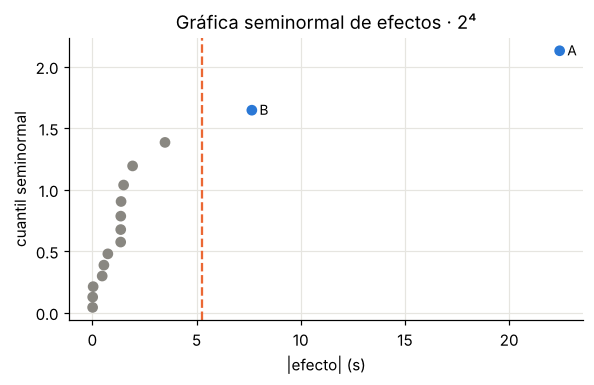

,contraste,estimado_2k4-1,efecto_2k4,alias_en_2k4,suma_2k4,diferencia
0,A + BCD,-22.9776,-22.4241,-0.5535,-22.9776,0.0000
1,B + ACD,-7.6902,-7.6528,-0.0375,-7.6903,0.0000
2,AB + CD,3.4738,3.4858,-0.0120,3.4737,0.0000
3,AD + BC,2.7228,1.3593,1.3635,2.7228,0.0000
4,C + ABD,-1.9151,-1.9307,0.0157,-1.9151,0.0000
5,AC + BD,0.7565,1.4992,-0.7427,0.7565,-0.0000
6,D + ABC,0.0164,1.3777,-1.3613,0.0164,0.0000


Activos en el 2^4 (Lenth): ['A', 'B']
Ahorro de la fracción: 8 de 16 corridas (50 %) · tiempo de máquina 223.3 s contra 442.9 s (49.6 % menos)


In [15]:
F4 = ["procesos", "parser", "formato", "lote"]
ruta4 = doe.RESULTADOS / "2k4.csv"
if ruta4.exists():
    d4 = pd.read_csv(ruta4)
    ef4 = doe.efectos_sin_replica(d4, F4)
    display(ef4)
    # Gráfica seminormal (Daniel): los efectos activos se separan de la recta
    orden_ef = ef4.assign(abs_ef=ef4["efecto"].abs()).sort_values("abs_ef")
    me = ef4["ME_lenth"].iloc[0]
    q = stats.halfnorm.ppf((np.arange(1, len(orden_ef) + 1) - 0.5) / len(orden_ef))
    fig, ax = plt.subplots(figsize=(5.5, 3.6))
    ax.scatter(orden_ef["abs_ef"], q, color=[AZUL if v > me else GRIS for v in orden_ef["abs_ef"]])
    for v, qq, t in zip(orden_ef["abs_ef"], q, orden_ef["termino"], strict=False):
        if v > me:
            ax.annotate(t, (v, qq), textcoords="offset points", xytext=(5, -3), fontsize=9)
    ax.axvline(ef4["ME_lenth"].iloc[0], color=NARANJA, ls="--", lw=1.5)
    ax.set_xlabel("|efecto| (s)")
    ax.set_ylabel("cuantil seminormal")
    ax.set_title("Gráfica seminormal de efectos · 2⁴")
    plt.tight_layout()
    plt.show()
    comp = doe.comparar_completo_vs_fraccion(d4)
    display(comp)
    sig_full = set(ef4.loc[ef4["significativo_lenth"], "termino"])
    fr = d4[d4["en_media_fraccion"]]
    ef_fr = doe.efectos_sin_replica(fr, F4)
    t_completo = d4["tiempo_s"].sum()
    t_fraccion = fr["tiempo_s"].sum()
    print(f"Activos en el 2^4 (Lenth): {sorted(sig_full)}")
    print(
        f"Ahorro de la fracción: 8 de 16 corridas (50 %) · tiempo de máquina {t_fraccion:.1f} s contra {t_completo:.1f} s "
        f"({100 * (1 - t_fraccion / t_completo):.1f} % menos)"
    )
else:
    print("Falta correr el 2^4: python -m laboratorio.experimento correr --diseno 2k4 --bloque 2 --sesion ...")

## 7. Corrida de confirmación

En una sesión nueva se corren 5 veces la mejor configuración y 5 la actual, intercaladas al azar. Se confirma si la razón observada (cociente de medias geométricas) cae dentro del intervalo de predicción de la sección 4 y si la tasa de error es la esperada.

In [16]:
ruta_c = doe.RESULTADOS / "confirmacion.csv"
if ruta_c.exists():
    conf = pd.read_csv(ruta_c)
    display(
        conf[["sesion", "orden", "configuracion", "procesos_valor", "parser_valor", "formato_valor", "tiempo_s", "tasa_error"]]
    )
    gm = conf.groupby("configuracion")["tiempo_s"].apply(lambda s: float(np.exp(np.log(s).mean())))
    obs = gm["actual"] / gm["mejor"]
    dentro = rz["ip95"][0] <= obs <= rz["ip95"][1]
    print(
        f"Sesión: {conf['sesion'].iloc[0]} · tiempos medios (geométricos): actual {gm['actual']:.2f} s, mejor {gm['mejor']:.2f} s"
    )
    print(
        f"Razón observada: {obs:.2f} veces más rápido · predicha {rz['razon']:.2f}, intervalo de predicción 95 % "
        f"[{rz['ip95'][0]:.2f}, {rz['ip95'][1]:.2f}] → {'SE CONFIRMA' if dentro else 'NO se confirma: revisar el modelo'}"
    )
    print("Tasa de error por configuración:", conf.groupby("configuracion")["tasa_error"].unique().to_dict())
else:
    print(
        "Falta la confirmación: python -m laboratorio.experimento confirmar --procesos 4 --parser lxml --formato csv --sesion ..."
    )

,sesion,orden,configuracion,procesos_valor,parser_valor,formato_valor,tiempo_s,tasa_error
0,viernes noche confirmacion,1,mejor,4,lxml,csv,5.8330,5.0030
1,viernes noche confirmacion,2,mejor,4,lxml,csv,5.7212,5.0030
2,viernes noche confirmacion,3,actual,1,html.parser,csv,19.7098,8.4950
3,viernes noche confirmacion,4,mejor,4,lxml,csv,5.7491,5.0030
4,viernes noche confirmacion,5,mejor,4,lxml,csv,5.6186,5.0030
5,viernes noche confirmacion,6,mejor,4,lxml,csv,5.6093,5.0030
6,viernes noche confirmacion,7,actual,1,html.parser,csv,19.7410,8.4950
7,viernes noche confirmacion,8,actual,1,html.parser,csv,19.8289,8.4950
8,viernes noche confirmacion,9,actual,1,html.parser,csv,19.7465,8.4950
9,viernes noche confirmacion,10,actual,1,html.parser,csv,19.7984,8.4950


Sesión: viernes noche confirmacion · tiempos medios (geométricos): actual 19.76 s, mejor 5.71 s
Razón observada: 3.46 veces más rápido · predicha 3.36, intervalo de predicción 95 % [3.14, 3.59] → SE CONFIRMA
Tasa de error por configuración: {'actual': array([8.495]), 'mejor': array([5.003])}


## 8. Conclusiones

1. **Mejor combinación: 4 procesos + `lxml` + CSV.** Es **3.36 veces más rápida** que la configuración actual (IC 95 % de 3.18 a 3.54): **70 % menos tiempo** para leer las 220 páginas. La ventaja se repitió en las 3 sesiones (de 3.19 a 3.50 veces).
2. **También lee mejor.** La tasa de error baja de 8.495 % a 5.003 % (2,327 filas más bien leídas por corrida). Toda la diferencia viene de las páginas con celdas sin `</td>`, que `html.parser` guarda **con contenido equivocado y sin avisar**. Se comprobó con la página real del SNIIM: al quitarle los `</td>`, `html.parser` devuelve filas como `"03/11/2026Caja de 19 kg.Colima…"` y `lxml` la lee igual que la original (prueba `test_celdas_sin_cierre_se_leen_bien_con_el_parser_elegido_en_e2`).
3. **Lo que importa son A (procesos) y B (parser)**, con una interacción AB pequeña: `lxml` ayuda más con un solo proceso. **El formato (C) no importa** (p = 0.64) y en el 2⁴ **el lote (D) tampoco**: no vale la pena cambiarlos.
4. **El bloqueo fue necesario.** La sesión de la tarde fue unas 2.4 veces más lenta en todas las configuraciones; el bloque explica tanta variación como los procesos. Sin bloquear, ese ruido habría tapado el efecto del parser. Por ese efecto multiplicativo, y por Box-Cox (λ = −0.16), el modelo final es log(tiempo).
5. **Agregar procesos rinde cada vez menos.** De 1 a 2 procesos se ahorra 43 % del tiempo; de 2 a 4, otro 35 %. Arrancar procesos tiene un costo fijo. En el bifactorial, la interacción procesos × parser queda en el límite (p = 0.051): la ventaja de `lxml` es un poco mayor con menos procesos, la misma dirección que la interacción AB del 2³ (p = 0.005), porque con más procesos una parte mayor del tiempo es arrancarlos, y ese costo no depende del parser.
6. **La media fracción 2⁴⁻¹ habría bastado.** Con 8 corridas en vez de 16 (49.6 % menos tiempo de máquina) identifica los mismos efectos activos (A y B). Su costo es que confunde las interacciones dobles por pares (AB = CD, AC = BD, AD = BC); aquí no afecta porque C y D no hacen nada.
7. **Confirmación.** En una sesión nueva, 5 corridas de cada configuración intercaladas al azar dieron **3.46 veces más rápido**, dentro del intervalo de predicción de 95 % (de 3.14 a 3.59). **El modelo se confirma.** La confirmación se corrió 45 minutos después del bloque 3, en condiciones parecidas a las de esa sesión; como se mide la razón entre configuraciones, el resultado no depende de la sesión.

**Qué se cambió en el sistema.** El extractor del SNIIM usa ahora `lxml` (`extractores/sniim.py`, constante `PARSER_HTML`). Los 4 procesos **no** se aplican a la captura en línea: ahí el cuello de botella es la red y el compromiso ético de E0 (una petición a la vez, con pausa de 1.5 s) manda sobre la velocidad. El hallazgo de los procesos sirve para reprocesar páginas guardadas.

**Límites.** Un banco local con 220 páginas y todas las corridas en el mismo equipo de medición (condición controlada del experimento: el resultado vale para ese tipo de equipo); las filas de otros mercados son sintéticas (derivadas de las de Colima) para que cada página tenga el tamaño de una respuesta real. La tasa de error depende de qué daños se incluyeron (12 % de páginas dañadas); su **dirección** (`lxml` lee mejor) está demostrada con la página real, pero su **magnitud** depende de qué tan seguido el SNIIM entregue HTML mal formado.